# Timeseries — Deteksi Anomali
**Kapan dipakai:** satu deret waktu (sensor, transaksi, trafik) dan diminta menandai titik yang
tidak wajar. Label anomali biasanya sangat sedikit atau tidak ada.

**Langkah:** tiap titik diberi fitur jendela (`WINDOW` nilai terakhir) → model anomali dilatih
di 70% awal → skor di 30% akhir. Skor makin tinggi makin anomali; ambang = kuantil
`PERCENTILE` dari skor uji. Pembanding tanpa model: z-score rolling.

**Data demo:** jumlah penumpang taksi NYC per 30 menit, label anomali di `is_anomaly`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyod.models.ecod import ECOD
from pyod.models.hbos import HBOS
from pyod.models.knn import KNN
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/timeseries/anomaly"   # GANTI saat lomba
SERIES_CSV = f"{DATA_FOLDER}/nyc_taxi.csv"

TIME_COL = "timestamp"
VALUE_COL = "value"
LABEL_COL = "is_anomaly"     # 1 = anomali
WINDOW = 48           # jendela 48 titik x 30 menit = 1 hari
TRAIN_FRACTION = 0.7  # 70% awal untuk latih, 30% akhir untuk uji
PERCENTILE = 0.95     # 5% skor tertinggi = anomali (tetap, tidak dituning di data uji)
SEED = 42

## Baca data dan EDA

(10320, 2) | proporsi anomali: 0.1


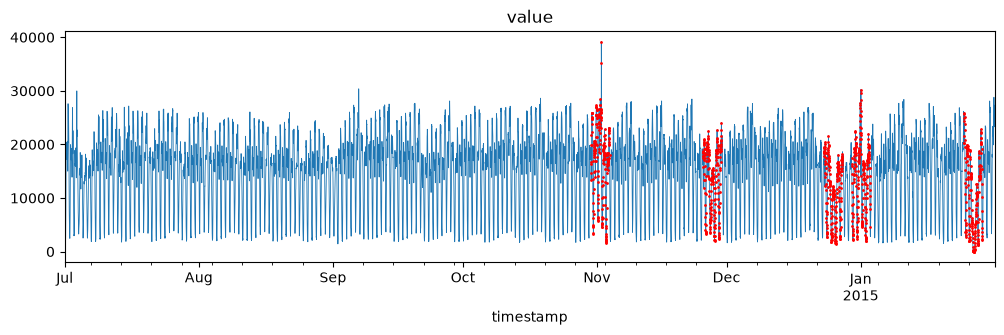

In [3]:
table = pd.read_csv(SERIES_CSV, parse_dates=[TIME_COL], index_col=TIME_COL)
values = table[VALUE_COL]
labels = table[LABEL_COL]
print(table.shape, "| proporsi anomali:", round(labels.mean(), 3))

ax = values.plot(figsize=(12, 3), lw=0.6, title=VALUE_COL)
values[labels == 1].plot(ax=ax, style=".", color="red", markersize=2, label="anomali")
plt.show()

## Fitur jendela, split waktu, dan z-score rolling (pembanding)
z-score = jarak nilai dari rata-rata `WINDOW` titik sebelumnya, dalam satuan simpangan baku.

In [4]:
features = pd.DataFrame(index=values.index)
for step in range(WINDOW):
    features[f"lag_{step}"] = values.shift(step)
features = features.dropna()

previous = values.shift(1).rolling(WINDOW)
z_score = (values - previous.mean()) / previous.std()

split_time = values.index[int(len(values) * TRAIN_FRACTION)]
X_train = features[features.index < split_time]
X_test = features[features.index >= split_time]
y_test = labels.loc[X_test.index]
print("latih:", len(X_train), "| uji:", len(X_test))
print("proporsi anomali uji:", round(y_test.mean(), 3))

latih: 7176 | uji: 3097
proporsi anomali uji: 0.221


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris IsolationForest.
Model sklearn: `decision_function` besar = normal, jadi diberi tanda minus.
Model PyOD (KNN, ECOD, HBOS): besar = anomali, **hapus tanda minus** di baris `scores`.

In [5]:
model = IsolationForest(n_estimators=200, random_state=SEED)
# model = LocalOutlierFactor(n_neighbors=20, novelty=True)
# model = OneClassSVM(nu=0.05, gamma="scale")
# model = EllipticEnvelope(random_state=SEED)
# model = KNN(n_neighbors=10)       # PyOD
# model = ECOD()                    # PyOD
# model = HBOS()                    # PyOD
model.fit(X_train)
scores = -model.decision_function(X_test)
# scores = z_score.abs().loc[X_test.index].to_numpy()     # pembanding tanpa model

## Evaluasi terhadap is_anomaly (data uji)

ambang: 0.0555
precision: 0.929
recall   : 0.21
F1       : 0.343
PR-AUC   : 0.495
PR-AUC acak (= proporsi anomali): 0.221


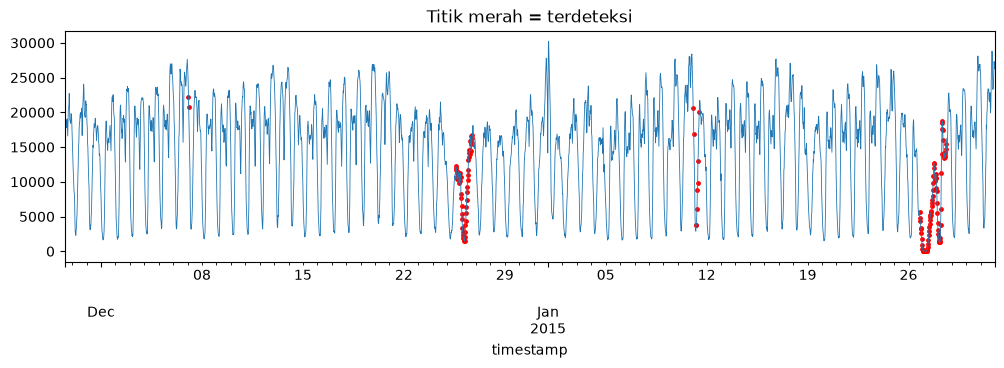

In [6]:
threshold = np.quantile(scores, PERCENTILE)
predictions = (scores >= threshold).astype(int)
print("ambang:", round(threshold, 4))
print("precision:", round(precision_score(y_test, predictions), 3))
print("recall   :", round(recall_score(y_test, predictions), 3))
print("F1       :", round(f1_score(y_test, predictions), 3))
print("PR-AUC   :", round(average_precision_score(y_test, scores), 3))
print("PR-AUC acak (= proporsi anomali):", round(y_test.mean(), 3))

detected = X_test.index[predictions == 1]
ax = values.loc[X_test.index].plot(figsize=(12, 3), lw=0.6, title="Titik merah = terdeteksi")
ax.scatter(detected, values.loc[detected], s=6, color="red")
plt.show()

## Simpan hasil (tanpa latih ulang: uji berdasarkan waktu)

In [7]:
result = pd.DataFrame()
result["timestamp"] = X_test.index
result["skor"] = scores
result["prediksi"] = predictions
result.to_csv("hasil.csv", index=False)
result.head()

,timestamp,skor,prediksi
0,2014-11-28 11:30:00,0.033470,0
1,2014-11-28 12:00:00,0.036147,0
2,2014-11-28 12:30:00,0.032306,0
3,2014-11-28 13:00:00,0.034371,0
4,2014-11-28 13:30:00,0.034600,0
